In [2]:
%% Homework 1, SIOC 221a, 8 Oct 2026, Ely Dawson

In [6]:
function pier=Get2021PierData(date_start,date_end,file)
% a modification of the class code given to us. Updated for current version
% of MatLAB and changed for my own preferences. 
% 
% Alterations:
%   - changed vars names
%   - updated outdated code structs (datenum to datetime)
%   - specified 2021 data rather than 2020
%   - changed the dnum var to a cleaner form
% 
% Version 1.2, 8 Oct 2026, Ely J. Dawson
%

if nargin < 3 || isempty(file)
    file = FindPierFile();
end

time = ncread(file,'time');
temperature = ncread(file,'temperature');
pressure = ncread(file,'pressure');
dnum = datetime(time,"ConvertFrom","posixtime");

if nargin < 1
    i1 = 1:numel(dnum); %no dates given: return the whole record
else
    i1 = find(dnum > date_start & dnum < date_end);
end

pier.dnum = dnum(i1);
pier.temperature = temperature(i1);
pier.pressure = pressure(i1);
pier.readme = '2021 Pier data, SIO221a, function Get2021PierData.m';
end

function file = FindPierFile()
%Locate data/scripps_pier-2021.nc without hard-coding anybody's home
%directory. This function knows where IT lives, so the data must be its
%sibling: mha_code/ and data/ are both inside the class repo.
here = fileparts(mfilename('fullpath')); %.../SIO221a_Github_code_2026/mha_code
repo = fileparts(here); %.../SIO221a_Github_code_2026
sentinel = fullfile('data','scripps_pier-2021.nc');
candidates = {fullfile(repo,sentinel), ...
fullfile(getenv('SIO221A_ROOT'),sentinel)};
    for k = 1:numel(candidates)
        if isfile(candidates{k})
        file = candidates{k};
            return
        end
    end
error(['Could not find ' sentinel '.']);
end

pier=Get2021PierData

pier = struct with fields:
           dnum: [129244×1 datetime]
    temperature: [129244×1 single]
       pressure: [129244×1 single]
         readme: '2021 Pier data, SIO221a, function Get2021PierData.m'

In [7]:
%Question 1a: Read the temperature data, and produce a line plot of the 2021 temperatures with 
%appropriately labeled axes. What do you observe in this plot? 

% There is a large variety in the data on a daily basis. You can see the data fluctuate daily, 
% however you can also see an overall trend in the data throughout the year. 
% You can see the water get warmer heading towards the peak of summer (mid-July) before cooling down 
% into the winter. There is also a large drop in temperature at August 1st in the data which breaks 
% from the normal of what we are seeing in the data. 

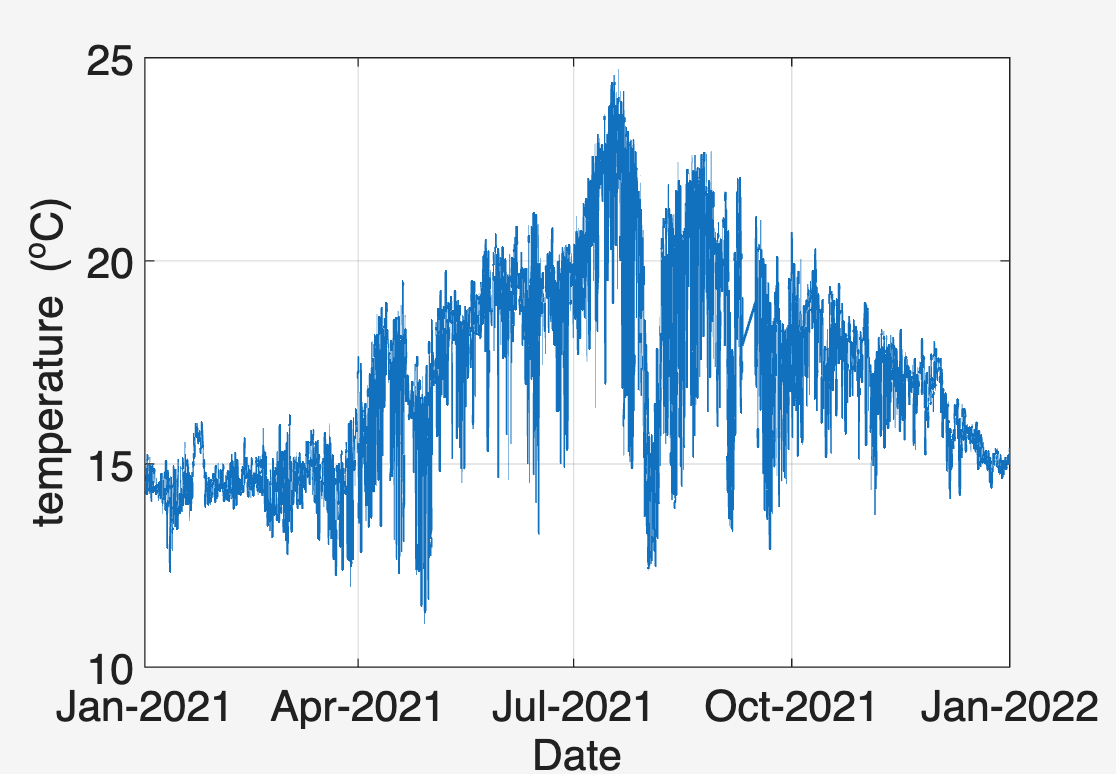

In [8]:
figure(1); clf;
plot(pier.dnum, pier.temperature, 'LineWidth', 1)
xticks('auto');
xtickformat('MMM-yyyy');
set(gca,'FontSize',16)
xlabel('Date','FontSize',16)
ylabel('Temperature (^oC)','FontSize',16)
grid on

In [4]:
% Question 1b: Compute the mean and standard deviation for the sea surface temperature data. 
% What do these statistics tell you about the temperature in 2021?

% These statistics tell us several things about the temperature in 2021. 
% The mean tells us the average over our time series. We can see that on average, the water temperature in 2021
% was around 17.3 °C with a standard deviation of 2.43 °C. This means that around 95% of the days had a surface temperature between 
% 12.44°C and 

In [2]:
mean_temp = mean(pier.temperature)

mean_temp = single
17.2740

In [3]:
stnd_temp = std(pier.temperature)

stnd_temp = single
2.4254